In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# Load CSV
csv_path = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/wandb_export_2026-03-20T09_02_08.757-04_00.csv")
raw = pd.read_csv(csv_path)

# Parse run columns: extract radius, mode, seed from column names
# Pattern: minr<radius>_<mode>_s<seed>_<runid> - eval/episode_mean_collected_treats
pattern = re.compile(
    r"^minr([\d.]+)_(.+?)_s(\d+)_.+ - eval/episode_mean_collected_treats$"
)

records = []
for col in raw.columns:
    m = pattern.match(col)
    if m:
        radius = float(m.group(1))
        mode = m.group(2)
        seed = int(m.group(3))
        # Get last non-empty value
        vals = pd.to_numeric(raw[col], errors="coerce").dropna()
        if len(vals) > 0:
            last_val = vals.iloc[-1]
            records.append(
                {"radius": radius, "mode": mode, "seed": seed, "collected_treats": last_val}
            )

df = pd.DataFrame(records)

# Map mode names to display names
mode_map = {
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
    "scratch": "Scratch",
}
df["Training Mode"] = df["mode"].map(mode_map)
df = df.sort_values("radius")
df

,radius,mode,seed,collected_treats,Training Mode
6,0.00,scratch,0,8.406250,Scratch
17,0.00,decoder_only,0,5.125000,Decoder-Only
20,0.00,prior_decoder,0,8.781250,Prior-Enabled
4,0.25,scratch,0,9.664062,Scratch
12,0.25,decoder_only,0,5.460938,Decoder-Only
19,0.25,prior_decoder,0,8.804688,Prior-Enabled
9,0.50,decoder_only,0,5.859375,Decoder-Only
5,0.50,scratch,0,9.570312,Scratch
18,0.50,prior_decoder,0,9.148438,Prior-Enabled
13,0.75,prior_decoder,0,9.335938,Prior-Enabled


Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/arena_forage_collected_treats.[pdf|svg|png]


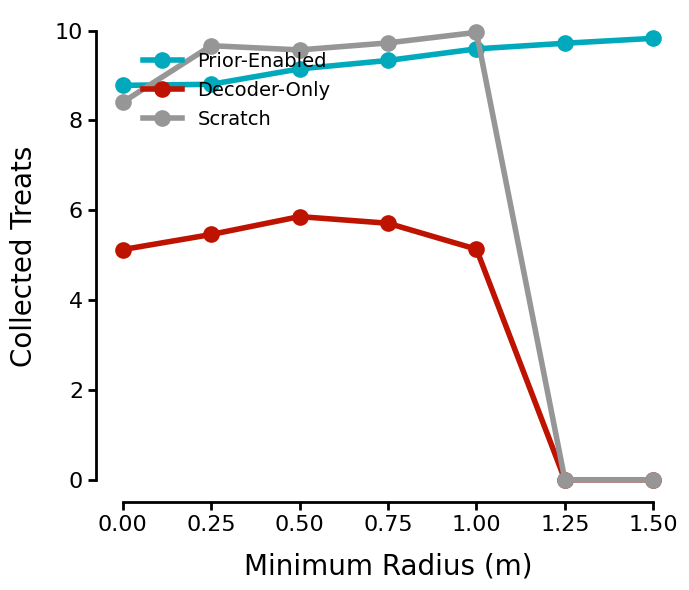

In [4]:
hue_order = ["Prior-Enabled", "Decoder-Only", "Scratch"]
palette = {
    "Prior-Enabled": tuple(c / 255 for c in (0, 170, 188)),
    "Decoder-Only": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}

save_name = "arena_forage_collected_treats"

fig, ax_main = plt.subplots(figsize=(7, 6))

# --- Main plot ---
sns.lineplot(
    data=df,
    x="radius",
    y="collected_treats",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    marker="o",
    markersize=12,
    markeredgewidth=0,
    linewidth=4,
    ax=ax_main,
)

ax_main.set_xlabel("Minimum Radius (m)", fontsize=20, labelpad=12)
ax_main.set_ylabel("Collected Treats", fontsize=20, labelpad=12)
ax_main.tick_params(labelsize=16, width=2, length=6)

# Remove top and right spines
sns.despine(ax=ax_main)

# Trim spines to start at the first tick and end at the last tick
xticks = ax_main.get_xticks()
yticks = ax_main.get_yticks()
xlim = ax_main.get_xlim()
ylim = ax_main.get_ylim()
xticks = [t for t in xticks if xlim[0] <= t <= xlim[1]]
yticks = [t for t in yticks if ylim[0] <= t <= ylim[1]]

ax_main.spines["bottom"].set_bounds(xticks[0], xticks[-1])
ax_main.spines["left"].set_bounds(yticks[0], yticks[-1])

# Thicken the remaining spines
for spine in ["left", "bottom"]:
    ax_main.spines[spine].set_linewidth(2)

ax_main.legend(
    fontsize=14, frameon=False, loc="upper left", bbox_to_anchor=(0.05, 0.95)
)

plt.tight_layout()

# Save
save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()